## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Juan Jose Vergara Rojas" # @param {"type":"string"}
carnet = 1000110044 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**


Una empresa desea administrar tareas tecnicas segun su prioridad y conectar varios dispositivos usando la menor cantidad total de cable, se tienen 6 tareas principalmente (configurar servidor, reparar sensor, actualizar software, revisar camara, generar respaldo y configurar alarma; haciendo el uso de algoritmos como el Max-heapify y build-max-heap.

## 2) Requerimientos **[2 pts]**

Lista requerimientos **funcionales** y **no funcionales**.



Requerimietos funcionales:
- Construir Max-heap a partir del listado inical de tareas tecnicas implementando Max-heapify y build-max-heap
- Construir una cola de prioridad usando Max - Heap 
- Mostrar el arreglo inicial y el arreglo organizado

Requerimientos no funcionales:
- Debe ser legible y documentado
- No se pueden usar librerias como un heapq
- El codigo debe ser modular. legible y que a lo ultimo al hacer las pruebas sean validas 

## 3) Historias de usuario **[2 pts]**
Escribe 3–5 historias de usuario con el formato visto en clase:
Incluye criterios de aceptación.


1. Construccion de cola de prioridad: Como operador quiero organizar las tareas pendientes en un max-heap segun su nivel de prioridad.
    
   - Criterio de aceptacion: Se muestra el arreglo original de 6 tareas y el arreglo ordenado tras el uso de build-max-heap

2. Procesamiento e incersion de emergencias: Como operador quiero extraer tareas de mayor prioridad y quiero insertar nnuevas incidencias criticas en el tiempo de ejecucion
    
   - Criterio de aceptacion: Se extraen T02 (10) y T04 (8) y luego se inserta T07 y queda en la raiz del Max-Heap

3. Mapeo y calculo de distancias de red: Quiero visualizar la coordenada de los 6 dispositivos y obtener la distancia entre ellos
   
   - Criterio de aceptacion: Se genera un grafico de dispersion con etiquetas y se calculan las 15 aristas

## 4) Diagramas de flujo **[5 pts]**
Incluye el diagrama que muestre el proceso general

Adjunta imagen y descríbelo claramente.


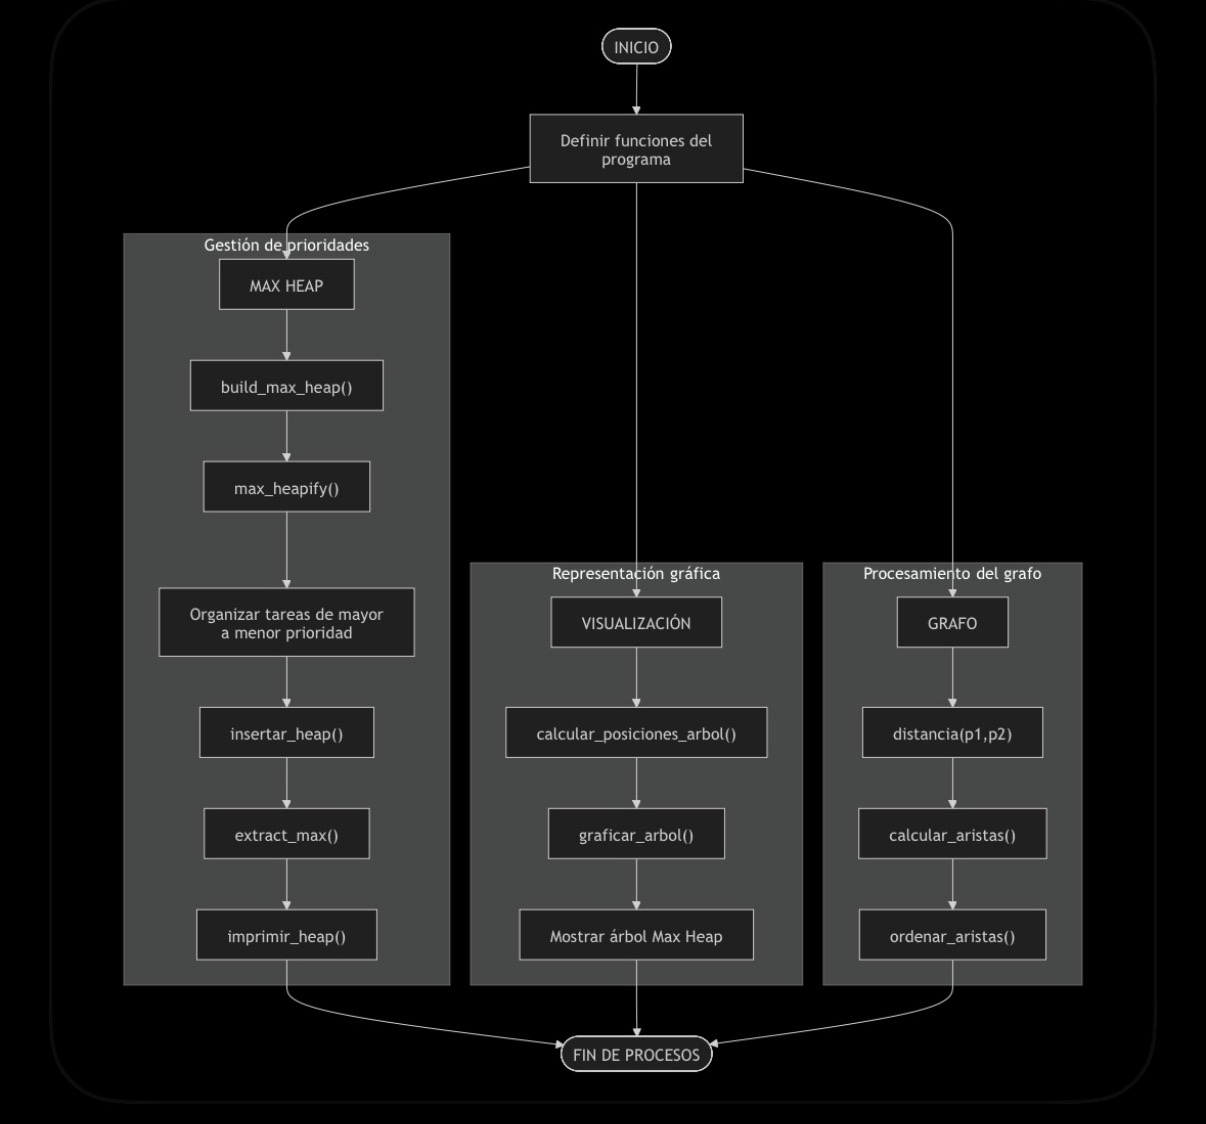

Explicacion: Al inicio define las funciones del programa que son 3 (gestion de prioridades, representacion grafica y el proesamiento del grafo) o los 3 caminos que va a tomar el programa, si agarra por gestion de prioridades aplica el max-heap, luego usa las dos funciones (build_max_heap() y max_heapify()), luego organiza las tareas de mayor a menor prioridad, inserta el heap. luego aplica extract_max() y por ultimo lo imprime.

Si agarra por la parte de la representacion grafica, primero calcula las posiciones del arbol, luego lo grafica y por ultimo lo muestra.

Y por ultimo, si agarra por el procesamiento del grafo, calcula primero las distancias (p1 y p2), luego calcula las aristas y por ultimo las ordena.

Ya cuando se acaba algun camino de los nombrados anteriormente, se acaba el programa 

### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
- Función T[n]
- Mejor y peor caso con gráfica


El analisis de complejidad de este problema es de O(log(n)), porque 

El mejor caso es O(log(n)) 
Y el peor es 

## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [ ]:
import matplotlib.pyplot as plt

def max_heapify(heap, n, i):
   mayor = i
   izq = 2 * i + 1
   der = 2 * i + 2
   if izq < n and heap[izq][2] > heap[mayor][2]:
       mayor = izq
   if der < n and heap[der][2] > heap[mayor][2]:
       mayor = der
   if mayor != i:
       heap[i], heap[mayor] = heap[mayor], heap[i]
       max_heapify(heap, n, mayor)

def build_max_heap(heap):
   n = len(heap)
   for i in range(n // 2 - 1, -1, -1):
       max_heapify(heap, n, i)

def extract_max(heap):
   if len(heap) == 0:
       return None
   mayor = heap[0]
   ultimo = heap.pop()
   if len(heap) > 0:
       heap[0] = ultimo
       max_heapify(heap, len(heap), 0)
   return mayor

def insertar_heap(heap, tarea):
   heap.append(tarea)
   i = len(heap) - 1
   while i > 0:
       padre = (i - 1) // 2
       if heap[i][2] > heap[padre][2]:
           heap[i], heap[padre] = heap[padre], heap[i]
           i = padre
       else:
           break

def imprimir_heap(titulo, heap):
   print(titulo)
   for t in heap:
       print(f"{t[0]} - {t[1]} | Prioridad: {t[2]}")
   print()

def calcular_posiciones_arbol(i, n, x, y, dx, pos):
   if i >= n:
       return
   pos[i] = (x, y)
   calcular_posiciones_arbol(2 * i + 1, n, x - dx, y - 1, dx / 2, pos)
   calcular_posiciones_arbol(2 * i + 2, n, x + dx, y - 1, dx / 2, pos)

def graficar_arbol(heap, titulo):
   n = len(heap)
   pos = {}
   calcular_posiciones_arbol(0, n, 0, 0, 2.0, pos)
   plt.figure(figsize=(8, 4))
   for i in range(n):
       x1, y1 = pos[i]
       for hijo in [2 * i + 1, 2 * i + 2]:
           if hijo < n:
               x2, y2 = pos[hijo]
               plt.plot([x1, x2], [y1, y2], "k-")
   for i in range(n):
       x, y = pos[i]
       cod, nom, prio = heap[i]
       plt.scatter(x, y, s=1100, color="lightblue", edgecolors="black")
       plt.text(x, y, f"{cod}\n{prio}", ha="center", va="center", fontweight="bold")
       plt.text(x, y - 0.3, nom, ha="center", fontsize=8)
   plt.title(titulo)
   plt.axis("off")
   plt.show()

def distancia(p1, p2):
   return ((p2[0] - p1[0]) ** 2 + (p2[1] - p1[1]) ** 2) ** 0.5

def calcular_aristas(dispositivos):
   ids = list(dispositivos.keys())
   aristas = []
   for i in range(len(ids)):
       for j in range(i + 1, len(ids)):
           u = ids[i]
           v = ids[j]
           p1 = (dispositivos[u][1], dispositivos[u][2])
           p2 = (dispositivos[v][1], dispositivos[v][2])
           d = distancia(p1, p2)
           aristas.append((u, v, d))
   return aristas

def ordenar_aristas(aristas):
   n = len(aristas)
   for i in range(n



## 7) Tests aplicados **[15 pts]**

In [ ]:
prueba_tareas = [
   ("T01", "Configurar servidor", 6),
   ("T02", "Reparar sensor", 10),
   ("T03", "Actualizar software", 4),
   ("T04", "Revisar cámara", 8),
   ("T05", "Generar respaldo", 3),
   ("T06", "Configurar alarma", 7)
]
build_max_heap(prueba_tareas)
assert prueba_tareas[0][0] == "T02"
assert prueba_tareas[0][2] == 10
ext1 = extract_max(prueba_tareas)
assert ext1[0] == "T02"
assert prueba_tareas[0][0] == "T04"
ext2 = extract_max(prueba_tareas)
assert ext2[0] == "T04"
assert prueba_tareas[0][0] == "T06"
insertar_heap(prueba_tareas, ("T07", "Falla en sistema contra incendios", 12))
assert prueba_tareas[0][0] == "T07"
assert prueba_tareas[0][2] == 12
assert len(prueba_tareas) == 5
prueba_dispositivos = {
   "A": ("Servidor", 2, 2),
   "B": ("Cámara", 7, 3),
   "C": ("Sensor", 4, 7),
   "D": ("Alarma", 10, 8),
   "E": ("Router", 13, 3),
   "F": ("Panel", 15, 7)
}
prueba_aristas = calcular_aristas(prueba_dispositivos)
assert len(prueba_aristas) == 15
prueba_mst, prueba_total = kruskal(prueba_dispositivos, prueba_aristas)
assert len(prueba_mst) == 5
assert round(prueba_total, 2) == 25.50
